# 06 · Resultados, comparación estadística y análisis

**Responsabilidad:** comparar A, B y C contra los baselines, contrastar las hipótesis con Wilcoxon e interpretar los comportamientos inesperados. Lee `results/`, que el notebook 05 verificó reproducible.

**Recordatorio de hipótesis** (notebook 00):
- **H₀:** la mediana de las diferencias de F1 entre dos políticas es 0.
- **H₁:** es distinta de 0.
- α = 0,05, prueba de Wilcoxon pareada sobre las 8 ventanas.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


In [2]:
wm = pd.read_csv("results/window_metrics.csv")
mv = pd.read_csv("results/model_versions.csv")
GR = ["A", "B", "C"]; BASE = ["siempre_sube", "persistencia", "estratificado"]
f1 = wm.pivot_table(index=["replica", "window_id"], columns="group", values="f1")[GR + BASE]

## 1. F1 por ventana: grupos vs baselines

group,A,B,C,siempre_sube,persistencia,estratificado
replica,,,,,,
logreg,0.557,0.548,0.516,0.685,0.521,0.528
rf,0.531,0.534,0.536,0.685,0.521,0.528


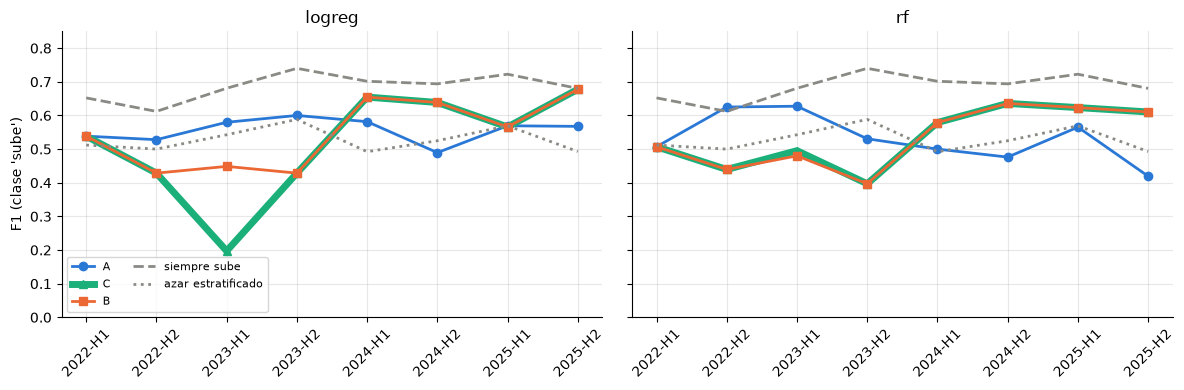

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, r in zip(axes, cfg.replicas):
    t = f1.loc[r]
    for g, lw in [("A", 2), ("C", 5), ("B", 2)]:
        ax.plot(t.index, t[g], marker=MARKER[g], color=COLOR[g], lw=lw, label=g)
    ax.plot(t.index, t.siempre_sube, ls="--", color=GRIS, label="siempre sube")
    ax.plot(t.index, t.estratificado, ls=":", color=GRIS, label="azar estratificado")
    ax.set_title(r); ax.tick_params(axis="x", rotation=45); ax.set_ylim(0, 0.85)
axes[0].set_ylabel("F1 (clase 'sube')"); axes[0].legend(ncol=2, fontsize=8); plt.tight_layout()
f1.groupby("replica").mean().round(3)

**Cómo leerlo:** cada línea es el F1 de un grupo por semestre. Las grises son las referencias: "siempre sube" (raya) y azar (puntos). La tabla da el promedio de las 8 ventanas.

**Qué concluimos:** **Ningún modelo supera a "siempre sube"** en ninguna ventana (0,685 de promedio contra ≈ 0,52–0,56 de los modelos). Contra el azar, los modelos apenas se separan. Las tres políticas tienen promedios muy parecidos.

## 2. Por qué "siempre sube" es tan difícil de vencer

Si se predice "sube" todos los días: Precision = p (la tasa real de subidas), Recall = 1 y **F1 = 2p/(1+p)**. El F1 de la clase "sube" ignora los días de bajada bien predichos, así que premia decir "sube" siempre (limitación declarada en D7, [17]).

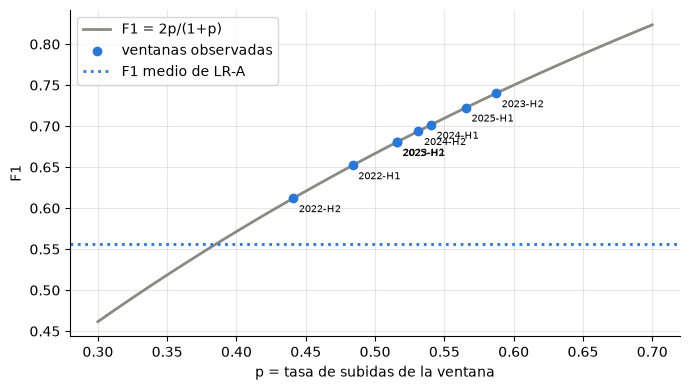

In [4]:
p = wm[wm.group == "siempre_sube"].groupby("window_id").precision.first()
xs = np.linspace(0.3, 0.7, 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, 2 * xs / (1 + xs), color=GRIS, label="F1 = 2p/(1+p)")
ax.scatter(p, f1.loc["logreg"].siempre_sube, color=COLOR["A"], zorder=3, label="ventanas observadas")
for wid in p.index: ax.annotate(wid, (p[wid], 2 * p[wid] / (1 + p[wid])), fontsize=7, xytext=(4, -10), textcoords="offset points")
ax.axhline(f1.loc["logreg"].A.mean(), color=COLOR["A"], ls=":", label="F1 medio de LR-A")
ax.set_xlabel("p = tasa de subidas de la ventana"); ax.set_ylabel("F1"); ax.legend(); plt.tight_layout()
assert np.allclose(2 * p / (1 + p), f1.loc["logreg"].siempre_sube)

**Cómo leerlo:** la curva es el F1 teórico de "siempre sube" según la tasa de subidas. Los puntos son las ventanas reales y caen exactamente sobre la curva.

**Qué concluimos:** Con p cerca de 0,5, el baseline trivial ya saca F1 ≈ 0,67, por encima del promedio de los modelos (línea punteada). Un F1 de 0,60 parece aceptable, pero aquí es **peor que no pensar**. Para trabajos futuros conviene usar métricas que no favorezcan una clase (MCC, balanced accuracy).

## 3. Diferencias por ventana y contraste de Wilcoxon

,replica,comparison,mean_diff_f1,windows_won,windows_lost,windows_tied,wilcoxon_statistic,p_value
0,logreg,B-A,-0.009,3,4,1,12.0,0.812
1,logreg,C-A,-0.041,3,4,1,11.0,0.688
2,logreg,B-C,0.031,1,0,7,0.0,1.000
3,rf,B-A,0.003,4,3,1,13.0,0.938
4,rf,C-A,0.005,4,3,1,13.0,0.938
5,rf,B-C,-0.002,0,1,7,0.0,1.000


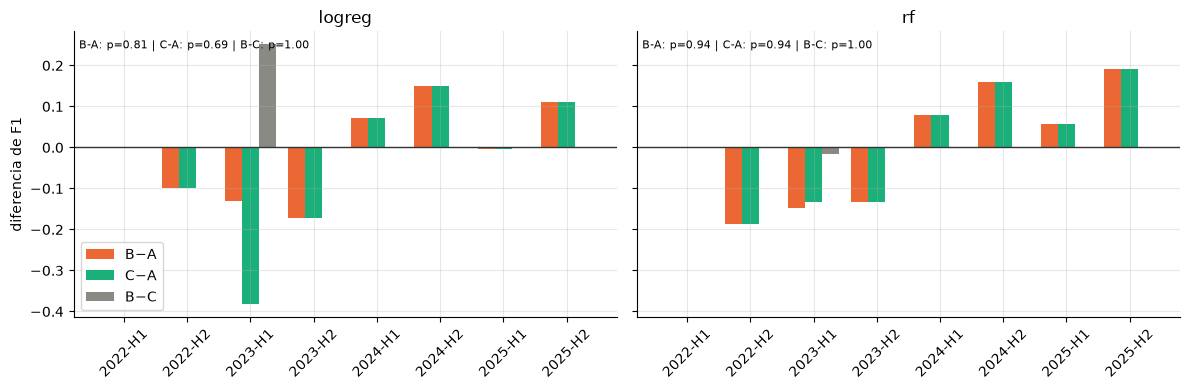

In [5]:
from msft_mlops.report import compare_groups
cmp = compare_groups(wm[wm.group.isin(GR)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
pares = [("B", "A"), ("C", "A"), ("B", "C")]; ancho = 0.27
for ax, r in zip(axes, cfg.replicas):
    t = f1.loc[r]; x = np.arange(len(t))
    for k, (g1, g2) in enumerate(pares):
        ax.bar(x + (k - 1) * ancho, t[g1] - t[g2], ancho, color=[COLOR["B"], COLOR["C"], GRIS][k], label=f"{g1}−{g2}")
    ax.axhline(0, color="#333", lw=1); ax.set_xticks(x, t.index, rotation=45); ax.set_title(r)
    pv = cmp[cmp.replica == r].set_index("comparison").p_value
    ax.text(0.01, 0.97, " | ".join(f"{c}: p={pv[c]:.2f}" for c in pv.index), transform=ax.transAxes, fontsize=8, va="top")
axes[0].set_ylabel("diferencia de F1"); axes[0].legend(); plt.tight_layout()
cmp[["replica", "comparison", "mean_diff_f1", "windows_won", "windows_lost", "windows_tied", "wilcoxon_statistic", "p_value"]]

**Cómo leerlo:** cada grupo de barras es una ventana. Una barra hacia arriba significa que la primera política ganó en esa ventana; hacia abajo, que perdió. Arriba se muestran los p-valores de Wilcoxon.

**Qué concluimos:** Las diferencias **cambian de signo**: B y C pierden en 2022–2023 y ganan en 2024–2025. Ganancias y pérdidas se compensan y todos los p son ≥ 0,69, así que **no se rechaza H₀** en ningún contraste. B−C es casi siempre 0 (7 empates de 8). **Importante:** no significativo ≠ iguales; con n = 8 la potencia es baja (Figura 5 del notebook 00). Además son 6 contrastes sin corrección por comparaciones múltiples.

## 4. La "dinámica bifásica": ¿mejor predicción o cambio de propensión?

El patrón de arriba (perder primero, ganar después) se llamó "dinámica bifásica". Hipótesis alternativa: el modelo reentrenado **copia la tasa de subidas del año con que se entrenó**. Tras un año bajista dice "sube" poco, lo que baja el recall; tras uno alcista lo dice casi siempre, lo que sube el recall.

,,recall,precision,f1
replica,,,,
logreg,p_subida_entrenamiento,0.948,-0.370,0.926
rf,p_subida_entrenamiento,0.757,0.278,0.750


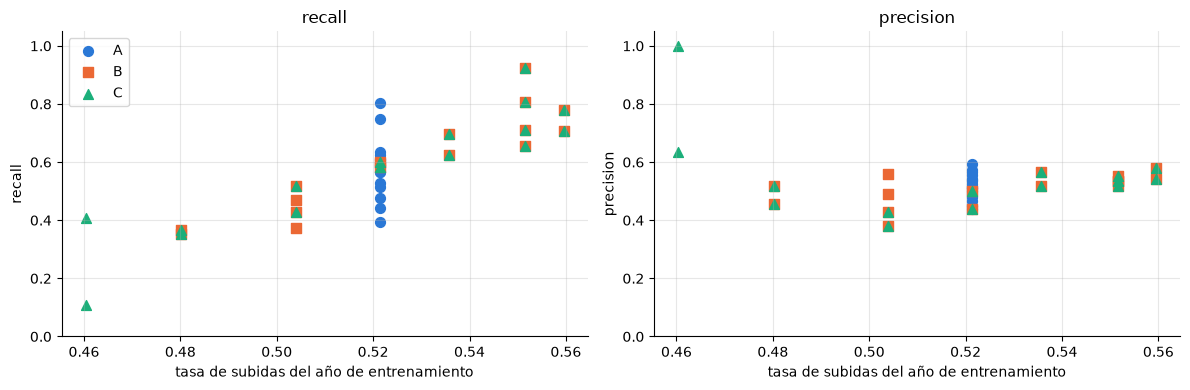

In [6]:
def tasa_entrenamiento(row):
    v = mv[(mv.replica == row.replica) & (mv.group == row.group) & (mv.version == row.version)].iloc[0]
    return ds.loc[v.train_start:v.train_end, "y"].mean()
g = wm[wm.group.isin(GR)].copy()
g["p_subida_entrenamiento"] = g.apply(tasa_entrenamiento, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, metric in zip(axes, ["recall", "precision"]):
    for grp in GR:
        s = g[g.group == grp]
        ax.scatter(s.p_subida_entrenamiento, s[metric], marker=MARKER[grp], color=COLOR[grp], s=50, label=grp)
    ax.set_xlabel("tasa de subidas del año de entrenamiento"); ax.set_ylabel(metric); ax.set_title(metric); ax.set_ylim(0, 1.05)
axes[0].legend(); plt.tight_layout()
g.groupby("replica")[["p_subida_entrenamiento", "recall", "precision", "f1"]].corr().loc[(slice(None), "p_subida_entrenamiento"), ["recall", "precision", "f1"]]

**Cómo leerlo:** cada punto es un grupo en una ventana. El eje horizontal es qué tan alcista fue el año con que se entrenó su modelo. A la izquierda el recall (cuántas subidas reales detectó) y a la derecha la precision (cuántas de sus predicciones de "sube" acertaron).

**Qué concluimos:** El recall **sube en línea** con la tasa de subidas del entrenamiento (correlación ≈ 0,95 en LR y ≈ 0,76 en RF), mientras la precision no se mueve (≈ 0,5). La "bifásica" se explica sobre todo por **cuánto dice "sube" el modelo**, no por mejor capacidad predictiva. Es un **retraso de régimen**: el modelo va un año atrasado respecto al mercado. No es sobreajuste medido.

## 5. B vs C: la única ventana donde difieren

In [7]:
d = wm[wm.group.isin(["B", "C"])].pivot_table(index=["replica", "window_id"], columns="group", values=["version", "f1", "recall", "n_pos_pred"])
d[d[("f1", "B")] != d[("f1", "C")]]

f1        n_pos_pred       recall        version     
group                  B      C          B     C      B      C       B    C
replica window_id                                                          
logreg  2023-H1    0.449  0.197       43.0   7.0  0.375  0.109     2.0  3.0
rf      2023-H1    0.480  0.495       61.0  41.0  0.469  0.406     2.0  3.0

**Qué concluimos:** en 2022-H2 la deriva no superó el umbral (p = 0,053), así que B **no** reentrenó y C sí, con datos de 2022. En 2023-H1 el modelo de C (LR) casi no predijo subidas: recall 0,11, con muy pocas predicciones de "sube". Fuera de esa ventana, B se comportó igual que C.

## 6. Conclusiones y confiabilidad

| Aspecto | Evaluación |
|---|---|
| Proceso (fuga, reproducibilidad, trazabilidad) | **Alta.** Sin fuga, idéntico bit a bit, con hashes y semilla |
| PI-1: ¿MLOps (B, C) mejora sobre el estático (A)? | **No demostrado.** p ≥ 0,69; diferencias que cambian de signo según el régimen |
| PI-2: ¿monitorear (B) aporta sobre reentrenar (C)? | **No discriminable.** KS + Bonferroni sobre features autocorrelacionadas salta casi siempre |
| Señal predictiva | **Nula frente al baseline trivial.** Ningún modelo supera a "siempre sube" |

**Amenazas a la validez:**
- Un solo activo y un solo periodo.
- n = 8 ventanas (baja potencia).
- El bootstrap y KS suponen independencia entre días.
- Hold-out corto (63 filas).
- Las dos réplicas usan los mismos datos (no son independientes).
- El F1 de la clase positiva favorece a "siempre sube".

## Trabajo futuro
- **Métricas financieras de costo-beneficio:** retorno de la estrategia contra comprar y mantener, con costos de transacción y Sharpe. Sirve para traducir las predicciones a valor monetario y fijar umbrales de reentrenamiento por costo.
- Métricas balanceadas: MCC o balanced accuracy ([17]).
- Disparador de deriva robusto a la autocorrelación (bloques o submuestreo) y más activos o periodos para ganar potencia.